In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
%matplotlib inline

#

## Calibrations

### Task 6.2.2 [2 absorbers with different temperatures]

In [12]:
def func_straight_line(x, m, c):
    """
    """
    return m*x + c # = y


In [3]:
T_absorber_hot = 22.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_hot = 0.5 + 273.15 # convert Celsius to Kelvin
T_absorber_cold = 1.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_cold = 0.5 + 273.15 # convert Celsius to Kelvin

P_cold_task622 = 42_006
errP_cold_task622 = 186
P_hot_task622 = 42_783
errP_hot_task622 = 105


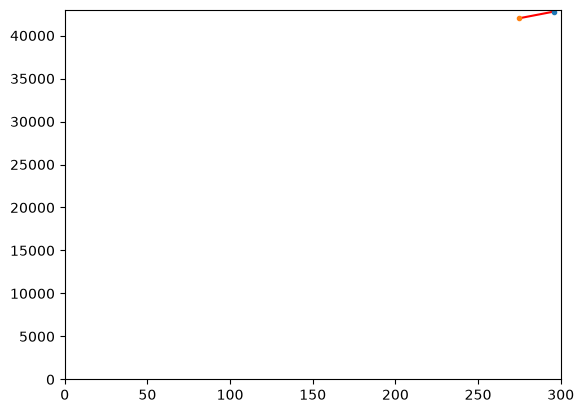

In [10]:
plt.plot(np.array([T_absorber_cold, T_absorber_hot]), np.array([P_cold_task622, P_hot_task622]), 'r-')

plt.plot(T_absorber_hot, P_hot_task622, '.')
plt.plot(T_absorber_cold, P_cold_task622, '.')

#plt.ylim(0, 43_000)
plt.xlim(0, 300);


$P_{absorber} = \alpha_{max}(T_{absober} + T_{sys}) = \alpha_{max}T_{absorber} + (\alpha_{max}T_{sys})$    
$y = mx + c$     
=> $m=\alpha_{max} = \frac{y_2-y_1}{x_2-x_1} = \frac{P_{absorber,hot}-P_{absorber,cold}}{T_{absorber,hot}-T_{absorber,cold}}$

In [11]:
print( (P_hot_task622-P_cold_task622)/(T_absorber_cold-T_absorber_hot) )

-37.0


$c = (\alpha_{max}T_{sys})$ => $T_{sys} = \frac{c}{\alpha_{max}}$

In [14]:
pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622])) 
            # will have to give uncertainties
# popt, pcov = curve_fit(function, xdata, ydata, sigma=yerr, absolute_sigma=True, p0=initial_pars)

#pars contains the fitted parameters
# => for fitfunc used here, pars[0] = m (slope) & pars[1] = c (intercept)
#cov = the covariance matrix & can be used to get the error on the slope & intercept
# => for fitfunc used here, np.sqrt(cov[0,0]) = err_slope & np.sqrt(cov[1,1]) = err_intercept
print(pars_task622[0], pars_task622[1])

36.99999999999996 31843.95000000001


C:\Users\cathe\AppData\Local\Temp\ipykernel_14512\4071669496.py:1: OptimizeWarning: Covariance of the parameters could not be estimated
  pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622]))


In [16]:
print(pars_task622[1]/pars_task622[0]) # T_sys = c/m


860.6472972972986


In [ ]:
# have to fit a line with error bars in *both* directions [error propagation is *not sufficient)